# Import Library, Load Data, and Setup

In [43]:
import pandas as pd
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import community.community_louvain as community_louvain
from pyvis.network import Network
import re 
from tqdm import tqdm
import scipy
import matplotlib.cm as cm
import matplotlib.patches as mpatches
import seaborn as sns
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
import squarify
import textwrap

pd.set_option('display.max_colwidth', None)

In [22]:
df_pati_final = pd.read_csv('output-data/bupati_pati_FINAL_FULL.csv')

df_pati_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2386 entries, 0 to 2385
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  2386 non-null   int64  
 1   conversation_id     2386 non-null   int64  
 2   source_tweet_id     1117 non-null   float64
 3   relation_type       2386 non-null   object 
 4   text                2386 non-null   object 
 5   author              2386 non-null   object 
 6   author_location     1449 non-null   object 
 7   created_at          2386 non-null   object 
 8   like_count          2386 non-null   int64  
 9   reply_count         2386 non-null   int64  
 10  retweet_count       2386 non-null   int64  
 11  quote_count         2386 non-null   int64  
 12  view_count          2386 non-null   int64  
 13  url                 2386 non-null   object 
 14  lang                2386 non-null   object 
 15  reply_to            1286 non-null   object 
 16  hashta

In [4]:
def extract_mentions(text):
    mentions = re.findall(r'@([A-Za-z0-9_]+)', str(text))
    return mentions

# Network Analysis

## Create Node

In [5]:
df_pati_final['reply_to'].unique()

array([nan, 'kompascom', 'Mustain88505110', 'edwinbazz', 'AkbarWasito',
       'AzzamIzzulhaq', 'doblang_08', 'callmeelily', 'akmalalhamm',
       'kumparan', 'Kuberahf', 'deBUGsy', 'zenday4hat', 'mrbintangpagi',
       'patiladen', 'PutuSambernyawa', 'jimans_', 'NurRohi03920969',
       'grok', 'AbelNov_', 'j0ny_yespapa', 'BarCk_14', 'ramydhia',
       'Heraloebss', 'GunawanBimo1701', 'kopilihdia', 'kajiseno',
       'willthesheeple', 'MurtadhaOne1', 'Budionotaslim3', 'afathngantuk',
       'BangJarwoSopo7', 'detikcom', 'Jateng_Twit', 'userataka',
       'jhonsitorus_19', 'DavidWijaya82', 'qc_wang1688', 'borntorun1717',
       'ekowboy2', 'AntoWahyudi17', 'FernaRondonuwu', 'GuitarsCute',
       'coxhaez', 'KaZep7', 'Hanz1843454', 'Hiugundul', 'nordianiz',
       'RakyatBerisik', 'EmilianoBuena', 'bangherwin', 'GardaGun',
       'Librathebest008', 'KuliPocok', 'OposisiOjol', 'laudanum68',
       '98d24ee59fa0405', 'MasfulPutra', 'Red_Lockey', 'Urrangawak',
       'whoisme25_', 'NasiAki

In [7]:
df_pati_final['relation_type'].value_counts()

relation_type
search_result    1269
reply             857
quote             252
main_tweet          8
Name: count, dtype: int64

In [8]:
results = []
print(f'[*] building network graph')

# handle nan values
df_pati_final['sentiment_keywords'] = df_pati_final['sentiment_keywords'].fillna('')
df_pati_final['sentiment_llm'] = df_pati_final['sentiment_llm'].fillna('NEUTRAL')
df_pati_final['reply_to'] = df_pati_final['reply_to'].fillna('') 

for index, row in tqdm(df_pati_final.iterrows(), total=df_pati_final.shape[0]):
    
    # extract basic tweet data
    user_source = row['author']
    tweet_text = row['text']
    
    # extract sentiment attributes
    sentiment_bert = row['sentiment']
    score_bert = row['score']
    sentiment_llm = row['sentiment_llm']
    keywords_llm = row['sentiment_keywords']
    
    # extract relation info
    rel_type = row['relation_type'] # reply, quote, search_result, main_tweet
    reply_target = str(row['reply_to']) # target username if exists
    
    list_target = set()
    interaction_weight = 1.0 # default weight
    final_interaction_type = 'mention' # default type
    
    # check for strong interactions (reply/quote)
    # prioritize reply_to column
    if reply_target != '' and reply_target != 'nan':
        # determine interaction type and weight
        if rel_type == 'quote':
            final_interaction_type = 'quote'
            interaction_weight = 2.0  # high weight
        elif rel_type == 'reply':
            final_interaction_type = 'reply'
            interaction_weight = 2.0  # high weight
        else:
            # fallback for search_results with reply_to
            final_interaction_type = 'reply'
            interaction_weight = 1.5 
            
        list_target.add(reply_target)

    # check mentions in text (secondary interaction)
    mentions_in_text = extract_mentions(tweet_text) 
    
    for mention in mentions_in_text:
        if mention != user_source: # avoid self-loop
            # skip if same as reply target to avoid duplication
            if mention != reply_target:
                # add mention edge (weight 1.0)
                results.append({
                    'source': user_source,
                    'target': mention,
                    'type': 'mention',
                    'weight': 1.0,
                    'sentiment_bert': sentiment_bert,
                    'score_bert': score_bert,
                    'sentiment_llm': sentiment_llm,
                    'keywords': keywords_llm,
                    'tweet_id': str(row['id']),
                    'tweet_url': row['url'],
                    'text': tweet_text
                })

    # add primary edge (reply/quote)
    for target in list_target:
        if user_source == target: continue
        
        results.append({
            'source': user_source,
            'target': target,
            'type': final_interaction_type,
            'weight': interaction_weight,
            'sentiment_bert': sentiment_bert,
            'score_bert': score_bert,
            'sentiment_llm': sentiment_llm,
            'keywords': keywords_llm,
            'tweet_id': str(row['id']),
            'tweet_url': row['url'],
            'text': tweet_text
        })

# create dataframe
df_edges = pd.DataFrame(results)

print(f'[*] generated {len(df_edges)} edges.')
print(f"[*] edge types distribution:\n{df_edges['type'].value_counts()}")
display(df_edges.head())

[*] building network graph


100%|██████████| 2386/2386 [00:00<00:00, 10175.42it/s]

[*] generated 1853 edges.
[*] edge types distribution:
type
reply      985
mention    619
quote      249
Name: count, dtype: int64


,source,target,type,weight,sentiment_bert,score_bert,sentiment_llm,keywords,tweet_id,tweet_url,text
0,solitaryans,kompascom,reply,2.0,Negative,0.999868,POSITIVE,"demo pajak naik, suap, perangkat desa, korupsi, rakus, tolol",2014298071509971005,https://x.com/solitaryans/status/2014298071509971005,"@kompascom dulu tuh pas didemo pajak naik udh mulai ke endus kasus2nya, skrg rame suap milyaran perangkat desa. tahan dulu lah anjing harusnya cari aman, timnya juga tolol norak ngapain video2.\nthose fat cunt are really dead greed"
1,nyoman_darmanto,kompascom,reply,2.0,Negative,0.999787,POSITIVE,"korupsi, sertifikat halal, menggarong",2013924708539081116,https://x.com/nyoman_darmanto/status/2013924708539081116,@kompascom Beginilah kalo korupsi sudah dapat sertifikat halal. Semua pada santai menggarong.
2,ubinhasnanto1,DPR_RI,mention,1.0,Neutral,0.999237,POSITIVE,"kpk, makzulkan, dpr mandul, pati, gerindra",2013787605368803668,https://x.com/ubinhasnanto1/status/2013787605368803668,@kompascom akhirnya di makzulkan oleh kpk dpr nya mandul @DPR_RI @kota_pati @Gerindra
3,ubinhasnanto1,kota_pati,mention,1.0,Neutral,0.999237,POSITIVE,"kpk, makzulkan, dpr mandul, pati, gerindra",2013787605368803668,https://x.com/ubinhasnanto1/status/2013787605368803668,@kompascom akhirnya di makzulkan oleh kpk dpr nya mandul @DPR_RI @kota_pati @Gerindra
4,ubinhasnanto1,Gerindra,mention,1.0,Neutral,0.999237,POSITIVE,"kpk, makzulkan, dpr mandul, pati, gerindra",2013787605368803668,https://x.com/ubinhasnanto1/status/2013787605368803668,@kompascom akhirnya di makzulkan oleh kpk dpr nya mandul @DPR_RI @kota_pati @Gerindra


## Build Visual with Networkx

In [9]:
# Create object
print('[*] initializing directed graph...')
G = nx.from_pandas_edgelist(
    df_edges,
    source='source',
    target='target',
    edge_attr=['type', 'weight', 'sentiment_bert', 'score_bert', 'sentiment_llm', 'keywords', 'tweet_id', 'tweet_url'],
    create_using=nx.DiGraph() # directed graph (arah panah penting)
)

print(f'[*] graph info: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges')

# network analysis
# in-degree: seberapa banyak orang me-reply/mention dia
# out-degree: seberapa rajin dia me-reply orang lain
in_degree = nx.in_degree_centrality(G)
out_degree = nx.out_degree_centrality(G)

# find the betweenness
betweenness = nx.betweenness_centrality(G)

# mencari orang2 yang terhubung lainnya
try:
    eigenvector = nx.eigenvector_centrality(G, max_iter=1000)
except:
    eigenvector = {n: 0 for n in G.nodes()}
    
# create community detection with louvain
print('[*] detecting communities...')
partition = community_louvain.best_partition(G.to_undirected())

nodes_data = []
for node in G.nodes():
    nodes_data.append({
        'id': node,
        'label': node,
        'in_degree': in_degree[node],
        'out_degree': out_degree[node],
        'betweenness': betweenness[node],
        'eigenvector': eigenvector[node],
        'community': partition[node]
    })

df_nodes = pd.DataFrame(nodes_data)

# sort by popularity (in-degree) to see top actors
df_nodes = df_nodes.sort_values(by='in_degree', ascending=False)

# save results
df_nodes.to_csv('output-data/network_nodes_metrics.csv', index=False)
nx.write_gexf(G, "graphs/bupati_pati_network.gexf") # file for gephi

print(f'[*] analysis done!')
print(f'[*] nodes metrics saved: output-data/network_nodes_metrics.csv')
print(f'[*] gephi file saved: graphs/bupati_pati_network.gexf')

# display top 5 influencers
print('\n[*] top 5 influencers (most mentioned/replied):')
display(df_nodes.head(5))

[*] initializing directed graph...
[*] graph info: 1264 nodes, 1595 edges
[*] detecting communities...
[*] analysis done!
[*] nodes metrics saved: output-data/network_nodes_metrics.csv
[*] gephi file saved: graphs/bupati_pati_network.gexf

[*] top 5 influencers (most mentioned/replied):


,id,label,in_degree,out_degree,betweenness,eigenvector,community
188,kumparan,kumparan,0.239113,0.000000,0.000000,0.000852,11
576,jhonsitorus_19,jhonsitorus_19,0.178147,0.007126,0.006219,0.612703,3
1,kompascom,kompascom,0.140143,0.000000,0.000000,0.004603,0
362,Heraloebss,Heraloebss,0.108472,0.006334,0.003244,0.001290,4
825,Urrangawak,Urrangawak,0.069675,0.003959,0.004594,0.220230,5


* hasil ini menunjukkan bahwa kumparan memiliki interaksi paling tinggi di antara yang lainnya terlihat dari score `in_degree` paling besar
* Kumparan & Kompas (Media) memiliki In-Degree tertinggi tetapi Out-Degree Nol. Artinya mereka berfungsi sebagai Sumber Isu. Orang membicarakan mereka, tapi mereka tidak ikut berdebat.
* Sementara secara interaksi dari user atau user membalas reply paling tinggi dari jhonsitorus_19 dilihat dari score `out_degree`
* jhonsitorus_19 dapat diartikan dia sebagai aktor yang berpengaruh di jaringan atau dia berada di tengah2 percakapan. Dengan kata lain, dialah yang "menggoreng" atau membesarkan isu dari media.

In [10]:
# check the buzz
display(df_nodes.sort_values(by='out_degree', ascending=False).head(5))

,id,label,in_degree,out_degree,betweenness,eigenvector,community
299,grok,grok,0.005542,0.111639,0.000729,2.689573e-04,1
724,pryambara28,pryambara28,0.000000,0.017419,0.000000,6.134090e-49,1
740,GardaGun,GardaGun,0.000792,0.015835,0.000002,4.907272e-47,1
576,jhonsitorus_19,jhonsitorus_19,0.178147,0.007126,0.006219,6.127026e-01,3
680,nordianiz,nordianiz,0.000792,0.006334,0.000011,3.707830e-25,22


* grok adalah noise karena dia bukan aktor politik, akun buzz, sekalipun manusia. Kehadiran hanya sebatas bot penjawab
* pryambara28 & GardaGun terlihat ditemukan beberapa kali sebagai amplifier atau spammer yang menandakan bahwa dua akun ini cukup ditemukan beberapa kali me-reply atau mentiong orang. Namun dua akun juga memiliki in_degree yang relatif sangat kecil, artinya tidak ada yang membalas atau mention dia balik.
* dua akun tersebut tidak bisa disebutkan langsung sebagai buzzer, tapi yang jelas dua akun tersebut cukup berisik untuk membalas. Motif atas tindakan tersebut perlu ditelaah lebih lanjut
* Aktor jhonsitorus_19 muncul lagi dalam top 5 berdasarkan score out_degree. Sama seperti sebelumnya, Dia bukan seperti Kumparan (yang cuma lempar berita lalu diam), dan bukan seperti pryambara28 (yang cuma teriak sendirian).
    * dia berperan dalam melempar isu
    * menjawab reply
    * tipe-tipe akun yang efektif sebagai "bahan bakar" di media sosial

**preview**

[*] calculating layout positions...
[*] rendering static preview...


C:\Users\ramad\AppData\Local\Temp\ipykernel_65584\2405945221.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20')


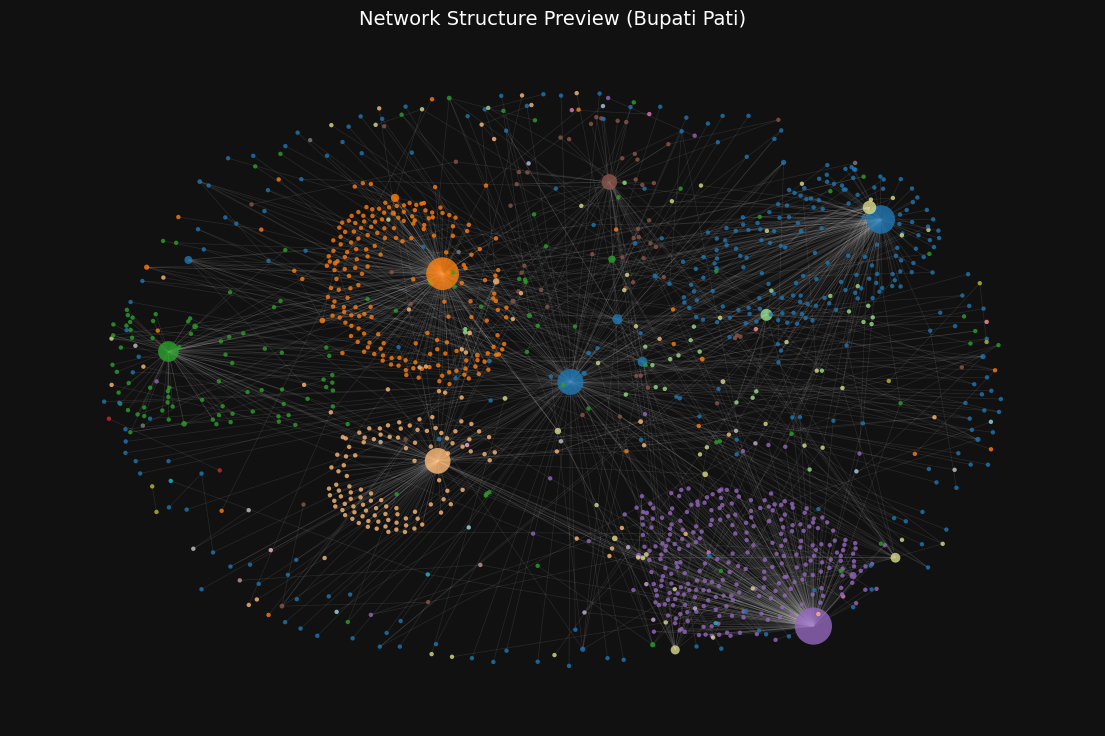

In [ ]:
plt.figure(figsize=(14, 9), facecolor='#111111') # dark background
ax = plt.gca()
ax.set_facecolor('#111111')

# calculate layout (spring algorithm)
# k=0.15 controls node spacing (smaller = tighter)
print("[*] calculating layout positions...")
pos = nx.spring_layout(G, k=0.15, seed=42)

# get community colors
# map community id to colors using a colormap (e.g., tab20)
if 'partition' in locals():
    node_communities = [partition.get(node) for node in G.nodes()]
    cmap = cm.get_cmap('tab20') 
else:
    node_communities = 'cyan' # fallback color
    cmap = None

# calculate node sizes based on popularity (degree)
# scale up for visibility, ensure min size of 10
node_sizes = [v * 3000 for v in nx.degree_centrality(G).values()]
node_sizes = [max(10, s) for s in node_sizes]

# draw edges (transparent white)
nx.draw_networkx_edges(
    G, pos, 
    alpha=0.1, 
    edge_color='white', 
    width=0.5, 
    arrows=False
)

# draw nodes (colored by community)
nodes = nx.draw_networkx_nodes(
    G, pos, 
    node_size=node_sizes, 
    node_color=node_communities, 
    cmap=cmap, 
    alpha=0.8, 
    linewidths=0
)

# final touches
plt.title('Network Structure Preview (Bupati Pati)', color='white', fontsize=14)
plt.axis('off')

print("[*] rendering static preview...")
plt.show()

C:\Users\ramad\AppData\Local\Temp\ipykernel_65584\6495779.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10') # use tab10 for high contrast


[*] rendering enhanced graph with labels & legend...


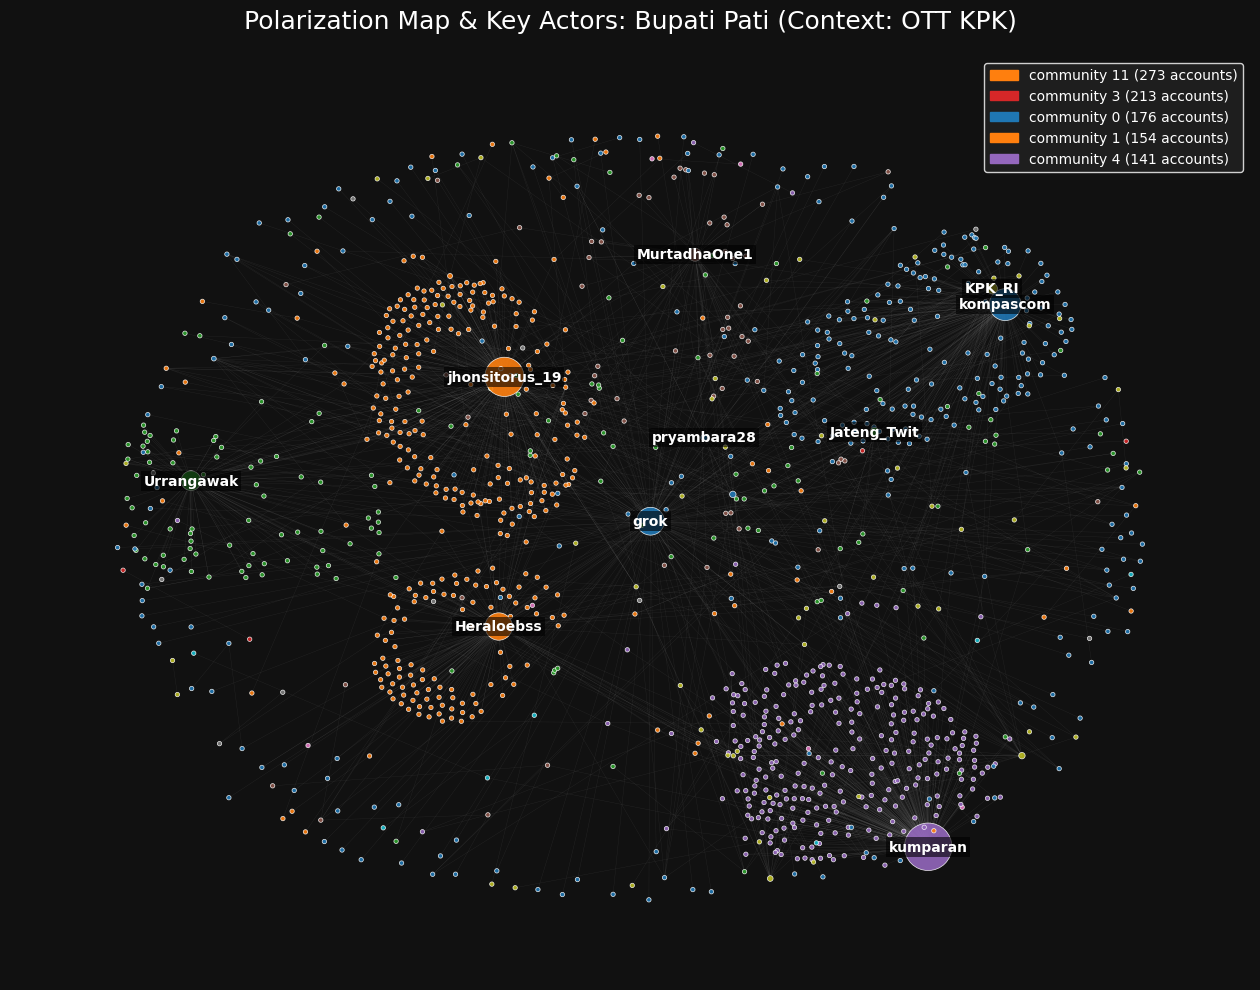

In [16]:
#visualization setup
plt.figure(figsize=(16, 12), facecolor='#111111') 
ax = plt.gca()
ax.set_facecolor('#111111')

# use pre-calculated layout for consistency
# calculate if 'pos' does not exist
if 'pos' not in locals():
    print("[*] calculating layout...")
    pos = nx.spring_layout(G, k=0.15, seed=42)

# get degree data for node sizing
degrees = dict(nx.degree_centrality(G))

# makes influencers look significantly larger than normal users
node_sizes = [v**1.5 * 10000 for v in degrees.values()] 
node_sizes = [max(10, s) for s in node_sizes] # ensure minimum size

# get community data for coloring
if 'partition' in locals():
    node_communities = [partition.get(node) for node in G.nodes()]
    cmap = cm.get_cmap('tab10') # use tab10 for high contrast
else:
    node_communities = 'cyan'
    cmap = None

# draw edges (thin & transparent)
nx.draw_networkx_edges(G, pos, alpha=0.08, edge_color='white', width=0.3, arrows=False)

# draw nodes
nodes = nx.draw_networkx_nodes(G, pos, 
                       node_size=node_sizes,
                       node_color=node_communities,
                       cmap=cmap,
                       alpha=0.9,
                       linewidths=0.5,
                       edgecolors='white') # add white border for pop-up effect

# label top 10 influencers only
# sort nodes by highest degree
top_nodes = sorted(degrees, key=degrees.get, reverse=True)[:10]
labels = {node: node for node in top_nodes} # create label dict for top 10

# draw labels
text_items = nx.draw_networkx_labels(G, pos, 
                        labels=labels, 
                        font_size=10, 
                        font_color='white',
                        font_weight='bold')

# add transparent black background for readability
for t in text_items.values():
    t.set_bbox(dict(facecolor='black', alpha=0.6, edgecolor='none', pad=2))

# create community legend (top 5 largest communities)
if 'partition' in locals():
    # count community members
    from collections import Counter
    comm_counts = Counter(partition.values())
    top_communities = comm_counts.most_common(5) # get top 5 communities
    
    legend_handles = []
    for comm_id, count in top_communities:
        # get color from colormap
        color = cmap(comm_id % 10) # match tab10 index
        # create manual legend label
        patch = mpatches.Patch(color=color, label=f'community {comm_id} ({count} accounts)')
        legend_handles.append(patch)
        
    plt.legend(handles=legend_handles, loc='upper right', facecolor='#222222', edgecolor='white', labelcolor='white')

# finishing
plt.title('Polarization Map & Key Actors: Bupati Pati (Context: OTT KPK)', color='white', fontsize=18, pad=20)
plt.axis('off')

print("[*] rendering enhanced graph with labels & legend...")
plt.show()

In [24]:
df_pati_final['sentiment_llm'].value_counts()

sentiment_llm
NEUTRAL     1181
POSITIVE     943
NEGATIVE     262
Name: count, dtype: int64

[*] rendering sentiment-based graph on white background...


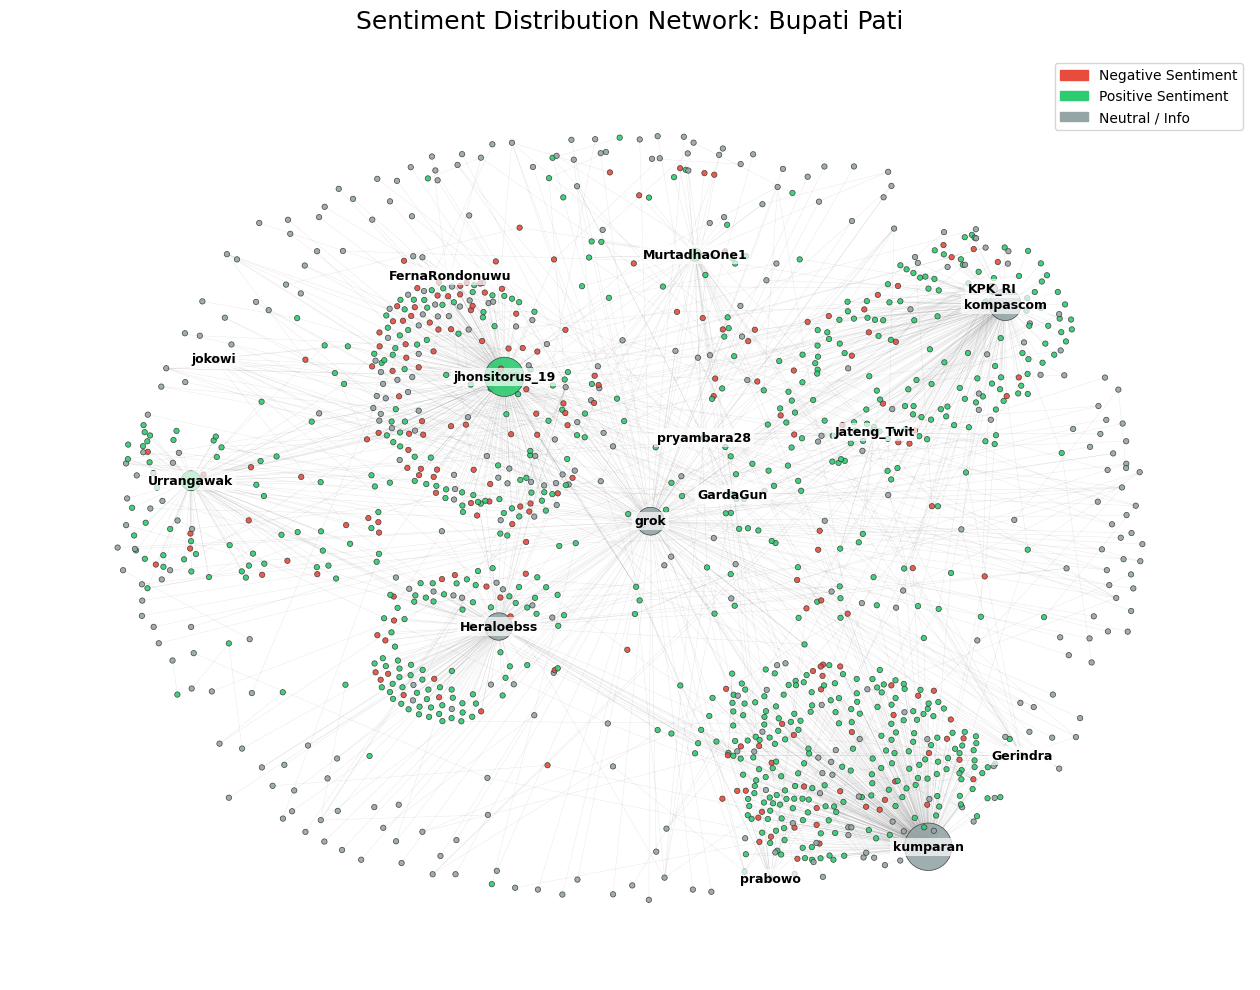

In [25]:
# creating a dictionary mapping author
author_sentiment_map = dict(zip(df_pati_final['author'], df_pati_final['sentiment_llm']))

# define color palette for sentiments
sentiment_colors = {
    'POSITIVE': '#2ecc71', # emerald green
    'NEGATIVE': '#e74c3c', # alizarin red
    'NEUTRAL': '#95a5a6',  # concrete grey
}

# generate color list for each node in the graph
node_colors = []
for node in G.nodes():
    # get sentiment, default to NEUTRAL if not found
    sent = author_sentiment_map.get(node, 'NEUTRAL').upper() 
    # map to color, default to grey if sentiment key is weird
    color = sentiment_colors.get(sent, '#95a5a6') 
    node_colors.append(color)

# visualization setup-
plt.figure(figsize=(16, 12), facecolor='white') 
ax = plt.gca()
ax.set_facecolor('white')

# calculate if 'pos' does not exist
if 'pos' not in locals():
    print("[*] calculating layout...")
    pos = nx.spring_layout(G, k=0.15, seed=42)

# get degree data for node sizing
degrees = dict(nx.degree_centrality(G))

# makes influencers look significantly larger than normal users
node_sizes = [v**1.5 * 10000 for v in degrees.values()] 
node_sizes = [max(15, s) for s in node_sizes] 

# draw edges (grey & transparent for white background)
nx.draw_networkx_edges(G, pos, 
                       alpha=0.15, # slightly more visible on white
                       edge_color='#555555', 
                       width=0.3, 
                       arrows=False)

# draw nodes (colored by sentiment)
nodes = nx.draw_networkx_nodes(G, pos, 
                       node_size=node_sizes,
                       node_color=node_colors,
                       alpha=0.9,
                       linewidths=0.5,
                       edgecolors='#333333') # dark grey border for contrast

# label top 15 influencers based on interaction amd sort nodes by highest degree
top_nodes = sorted(degrees, key=degrees.get, reverse=True)[:15]
labels = {node: node for node in top_nodes} 

# draw labels
text_items = nx.draw_networkx_labels(G, pos, 
                        labels=labels, 
                        font_size=9, 
                        font_color='black',
                        font_weight='bold')

# add transparent white background for readability on top of lines
for t in text_items.values():
    t.set_bbox(dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2))

# create sentiment legend
legend_handles = [
    mpatches.Patch(color=sentiment_colors['NEGATIVE'], label='Negative Sentiment'),
    mpatches.Patch(color=sentiment_colors['POSITIVE'], label='Positive Sentiment'),
    mpatches.Patch(color=sentiment_colors['NEUTRAL'], label='Neutral / Info')
]
plt.legend(handles=legend_handles, loc='upper right', frameon=True, facecolor='white', edgecolor='#cccccc')

# finishing
plt.title('Sentiment Distribution Network: Bupati Pati', color='black', fontsize=18, pad=20)
plt.axis('off')

print("[*] rendering sentiment-based graph on white background...")
plt.show()

[*] rendering sentiment-based graph on white background...


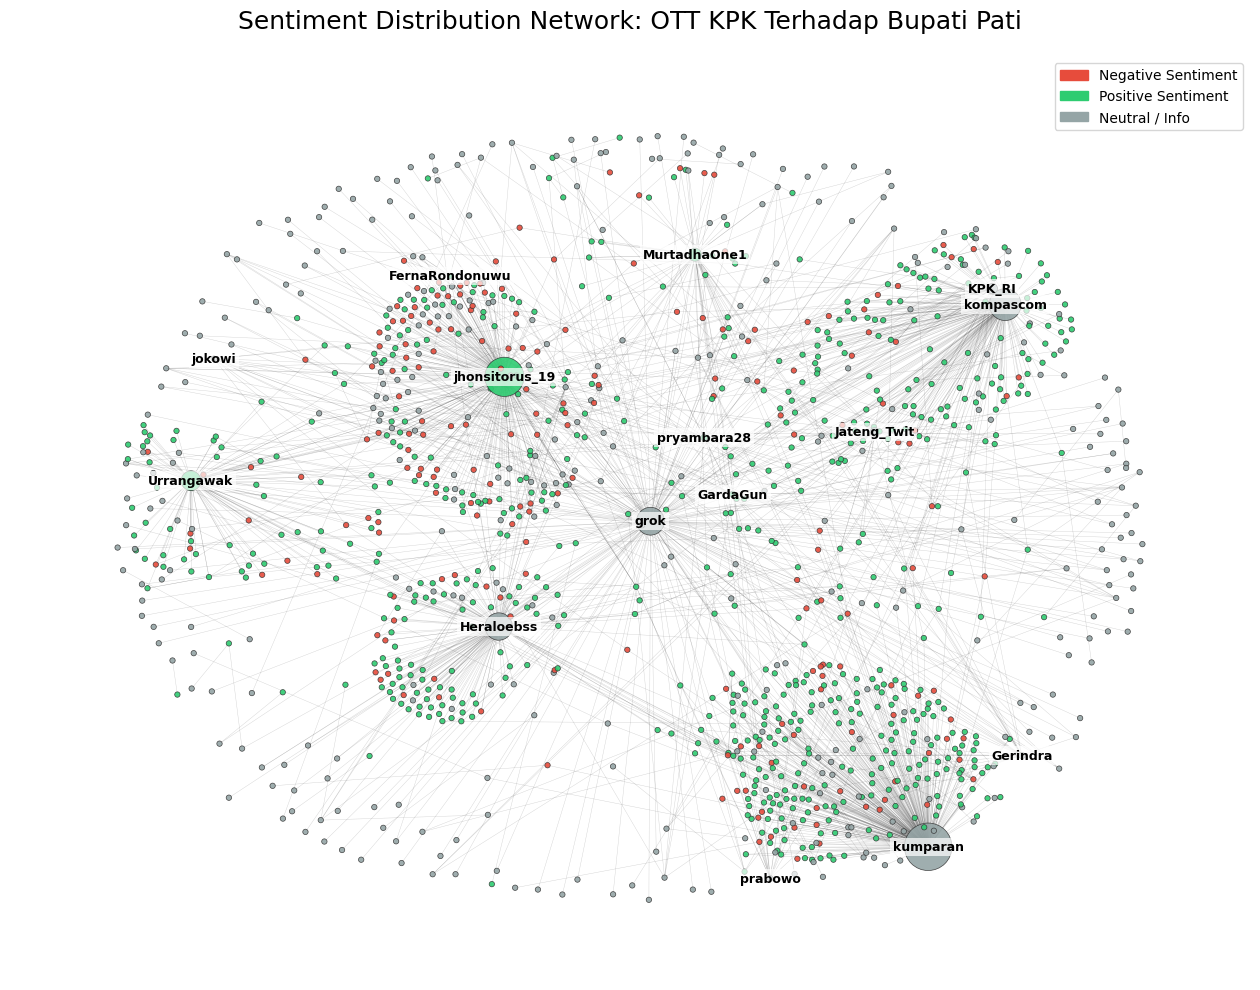

In [27]:
# creating a dictionary mapping author
author_sentiment_map = dict(zip(df_pati_final['author'], df_pati_final['sentiment_llm']))

# define color palette for sentiments
sentiment_colors = {
    'POSITIVE': '#2ecc71', 
    'NEGATIVE': '#e74c3c', 
    'NEUTRAL': '#95a5a6', 
}

# generate color list for each node in the graph
node_colors = []
for node in G.nodes():
    # get sentiment, default to NEUTRAL if not found
    sent = author_sentiment_map.get(node, 'NEUTRAL').upper() 
    # map to color, default to grey if sentiment key is weird
    color = sentiment_colors.get(sent, '#95a5a6') 
    node_colors.append(color)

# visualization setup
plt.figure(figsize=(16, 12), facecolor='white') 
ax = plt.gca()
ax.set_facecolor('white')

# calculate if 'pos' does not exist
if 'pos' not in locals():
    print("[*] calculating layout...")
    pos = nx.spring_layout(G, k=0.15, seed=42)

# get degree data for node sizing
degrees = dict(nx.degree_centrality(G))

# makes influencers look significantly larger than normal users
node_sizes = [v**1.5 * 10000 for v in degrees.values()] 
node_sizes = [max(15, s) for s in node_sizes] 

# draw edges (darker & slightly more visible on white)
nx.draw_networkx_edges(G, pos, 
                       alpha=0.2, # increased slightly for visibility
                       edge_color='#222222',
                       width=0.3, 
                       arrows=False)

# draw nodes (colored by sentiment)
nodes = nx.draw_networkx_nodes(G, pos, 
                       node_size=node_sizes,
                       node_color=node_colors,
                       alpha=0.9,
                       linewidths=0.5,
                       edgecolors='#333333') # dark grey border for contrast

# label top 15 influencers based on interaction amd sort nodes by highest degree
top_nodes = sorted(degrees, key=degrees.get, reverse=True)[:15]
labels = {node: node for node in top_nodes} 

# draw labels
text_items = nx.draw_networkx_labels(G, pos, 
                        labels=labels, 
                        font_size=9, 
                        font_color='black',
                        font_weight='bold')

# add transparent white background for readability on top of lines
for t in text_items.values():
    t.set_bbox(dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2))

# create sentiment legend
legend_handles = [
    mpatches.Patch(color=sentiment_colors['NEGATIVE'], label='Negative Sentiment'),
    mpatches.Patch(color=sentiment_colors['POSITIVE'], label='Positive Sentiment'),
    mpatches.Patch(color=sentiment_colors['NEUTRAL'], label='Neutral / Info')
]
plt.legend(handles=legend_handles, loc='upper right', frameon=True, facecolor='white', edgecolor='#cccccc')

# finishing
plt.title('Sentiment Distribution Network: OTT KPK Terhadap Bupati Pati', color='black', fontsize=18, pad=20)
plt.axis('off')

print("[*] rendering sentiment-based graph on white background...")
plt.show()

- Visualisasi jaringan menunjukkan dukungan mutlak publik (Dominasi Hijau) terhadap OTT KPK Bupati Pati. Tidak ditemukan polarisasi atau upaya pembelaan terorganisir (Absennya Cluster Merah/Negatif), mengindikasikan bahwa figur Sudewo telah kehilangan legitimasi politik sepenuhnya
- Interaksi terpusat pada Influencer Nasional (seperti jhonsitorus_19) yang mengamplifikasi narasi penegakan hukum, serta tekanan publik kepada entitas politik terkait (Gerindra, Prabowo) untuk mengambil sikap tegas terhadap kadernya.
- Munculnya node 'Jokowi' dalam jaringan percakapan ini bukan mengindikasikan keterlibatan langsung dalam kasus hukum, melainkan bentuk dari memori kolektif publik.
- Netizen sangat mungkin mengaitkan kasus OTT ini dengan jejak digital (digital footprint) berupa endorsement politik masa lalu ('Saya titip Pati...'). Hal ini menunjukkan bahwa dalam era media sosial, dukungan politik di masa lalu dapat ditarik kembali (recalled) oleh publik sebagai konteks relevan saat terjadi pelanggaran integritas --> Namun hal ini akan kita cari tahu lagi di wordcloud nantinya

# Sentiment Analysis

In [28]:
df_pati_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2386 entries, 0 to 2385
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  2386 non-null   int64  
 1   conversation_id     2386 non-null   int64  
 2   source_tweet_id     1117 non-null   float64
 3   relation_type       2386 non-null   object 
 4   text                2386 non-null   object 
 5   author              2386 non-null   object 
 6   author_location     1449 non-null   object 
 7   created_at          2386 non-null   object 
 8   like_count          2386 non-null   int64  
 9   reply_count         2386 non-null   int64  
 10  retweet_count       2386 non-null   int64  
 11  quote_count         2386 non-null   int64  
 12  view_count          2386 non-null   int64  
 13  url                 2386 non-null   object 
 14  lang                2386 non-null   object 
 15  reply_to            1286 non-null   object 
 16  hashta

In [33]:
pd.set_option('display.max_rows', None)

In [34]:
print(df_pati_final['author_location'].value_counts())

author_location
Indonesia                         230
Jakarta                           133
wherever you are                   78
Jakarta Capital Region             63
Jakarta, Indonesia                 34
Jakarta - Indonesia                29
Palmerah, Jakarta                  29
iNews Tower                        25
Yogyakarta                         21
Jakarta Pusat, DKI Jakarta         19
indonesia                          17
DKI Jakarta, Indonesia             17
NKRI                               15
Korea Utara                        13
Yogyakarta, Indonesia              13
Bogor, Jawa Barat                  11
Indonesia                          10
Jawa Tengah, Indonesia             10
🇮🇩                                 10
Gresik, Indonesia                  10
Jawa Tengah                         9
Padang                              9
Kota Surabaya, Jawa Timur           9
Ponorogo, Indonesia                 8
🇮🇩 Pancasila                        8
JKT-INA                           

output terlalu random, tidak jadi divisualkan

In [36]:
df_pati_final['created_at'] = pd.to_datetime(df_pati_final['created_at'])

print(df_pati_final['created_at'].min())
print(df_pati_final['created_at'].max())

C:\Users\ramad\AppData\Local\Temp\ipykernel_65584\1395383486.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_pati_final['created_at'] = pd.to_datetime(df_pati_final['created_at'])


2026-01-19 06:05:36+00:00
2026-01-24 10:15:53+00:00


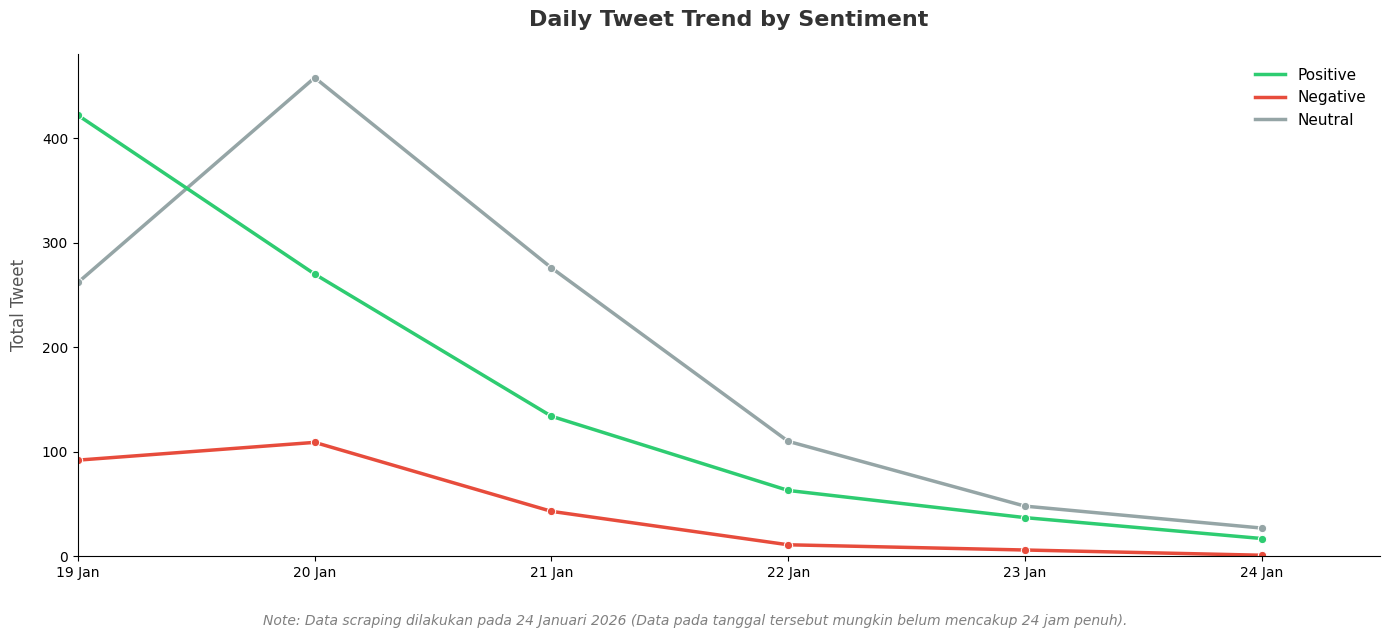

In [39]:
# ensure date is datetime
df_pati_final['created_at'] = pd.to_datetime(df_pati_final['created_at'])

# extract date only for daily grouping
df_pati_final['date_only'] = df_pati_final['created_at'].dt.date

# aggregate daily tweets by sentiment
daily_trend = df_pati_final.groupby(['date_only', 'sentiment_llm'])['id'].nunique().reset_index(name='total_tweet')

# ensure date is datetime again for plotting logic
daily_trend['date'] = pd.to_datetime(daily_trend['date_only'])

# fill missing dates with 0 to ensure continuous lines (pivot -> fillna -> melt)
pivot_df = daily_trend.pivot(index='date', columns='sentiment_llm', values='total_tweet').fillna(0)

# reindex to ensure all days in range exist (handling days with 0 tweets)
all_days = pd.date_range(start=daily_trend['date'].min(), end=daily_trend['date'].max(), freq='D')
pivot_df = pivot_df.reindex(all_days, fill_value=0)
pivot_df.index.name = 'date'

# melt back for seaborn
daily_trend_filled = pivot_df.reset_index().melt(id_vars='date', var_name='sentiment_llm', value_name='total_tweet')

# define colors based on request
sentiment_colors = {
    'POSITIVE': '#2ecc71', 
    'NEGATIVE': '#e74c3c', 
    'NEUTRAL': '#95a5a6', 
}


# visualize
plt.figure(figsize=(14, 6), facecolor='white')
ax = plt.gca()

# plot line chart
sns.lineplot(
    data=daily_trend_filled,
    x='date',
    y='total_tweet',
    hue='sentiment_llm',
    palette=sentiment_colors,
    linewidth=2.5,
    marker='o', # added marker to see data points clearly on short range
    legend=False
)

# standard linear scale, integer formatting
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
plt.ylabel('Total Tweet', fontsize=12, labelpad=10, color='#555555')

# x-axis daily
locator = mdates.DayLocator(interval=1) 
ax.xaxis.set_major_locator(locator)

# custom date formatter
def custom_date_formatter(x, pos):
    try:
        dt = mdates.num2date(x)
        month_map = {
            1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'Mei', 6: 'Jun',
            7: 'Jul', 8: 'Agu', 9: 'Sep', 10: 'Okt', 11: 'Nov', 12: 'Des'
        }
        return f"{dt.day} {month_map.get(dt.month, dt.strftime('%b'))}"
    except:
        return ""

ax.xaxis.set_major_formatter(ticker.FuncFormatter(custom_date_formatter))
plt.xlabel('') # remove x label

# create custom legend in top right
legend_elements = [
    Line2D([0], [0], color=sentiment_colors['POSITIVE'], lw=2.5, label='Positive'),
    Line2D([0], [0], color=sentiment_colors['NEGATIVE'], lw=2.5, label='Negative'),
    Line2D([0], [0], color=sentiment_colors['NEUTRAL'], lw=2.5, label='Neutral')
]

ax.legend(
    handles=legend_elements,
    loc='upper right',
    frameon=False, # transparent background
    fontsize=11
)

# styling and margins
plt.title('Daily Tweet Trend by Sentiment', fontsize=16, fontweight='bold', pad=20, loc='center', color='#333333')
plt.grid(False)
sns.despine()

# limits
min_date = daily_trend_filled['date'].min()
max_date = daily_trend_filled['date'].max()

# padding right slightly to not cut the last marker
plt.xlim(left=min_date, right=max_date + pd.Timedelta(hours=12))
plt.ylim(bottom=0)

# add custom note
note_text = "Note: Data scraping dilakukan pada 24 Januari 2026 (Data pada tanggal tersebut mungkin belum mencakup 24 jam penuh)."

plt.figtext(
    0.5, -0.05,
    note_text,
    ha="center",
    fontsize=10,
    style='italic',
    color='gray'
)

plt.tight_layout()
plt.show()

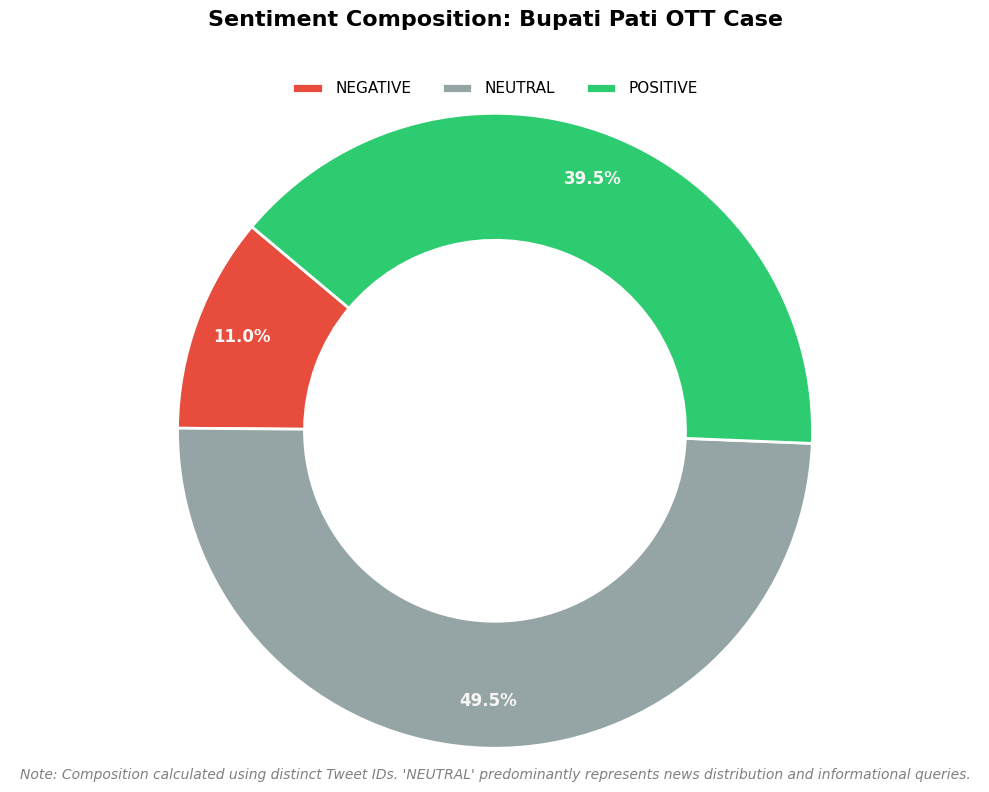

In [40]:
# define colors based on request
sentiment_colors = {
    'POSITIVE': '#2ecc71', 
    'NEGATIVE': '#e74c3c', 
    'NEUTRAL': '#95a5a6', 
}

# aggregate data using nunique to count distinct tweets
sentiment_counts = df_pati_final.groupby('sentiment_llm')['id'].nunique().reset_index(name='total_tweet')

# map colors to the specific order of data
colors = [sentiment_colors[sent] for sent in sentiment_counts['sentiment_llm']]

# visualize
plt.figure(figsize=(10, 8), facecolor='white')

# create donut chart
wedges, texts, autotexts = plt.pie(
    sentiment_counts['total_tweet'],
    labels=None,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    pctdistance=0.85,
    wedgeprops={'width': 0.4, 'edgecolor': 'white', 'linewidth': 2},
    textprops={'fontsize': 12, 'fontweight': 'bold', 'color': '#F6F6F5'}
)

# add title with extra padding to accommodate legend
plt.title('Sentiment Composition: Bupati Pati OTT Case', fontsize=16, fontweight='bold', pad=40)

# custom legend at top center
plt.legend(
    wedges,
    sentiment_counts['sentiment_llm'],
    title=None,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02), # moved up slightly
    ncol=3,
    frameon=False,
    fontsize=11
)

# clean up styles
plt.axis('equal')

# add technical note
note_text = "Note: Composition calculated using distinct Tweet IDs. 'NEUTRAL' predominantly represents news distribution and informational queries."

plt.figtext(
    0.5, 0.02, # moved further down
    note_text,
    ha="center",
    fontsize=10,
    style='italic',
    color='gray'
)

plt.tight_layout()
plt.show()

Grafik tren harian menunjukkan adanya Konsensus Dukungan Mutlak terhadap OTT KPK. Hal ini terlihat dari
1. Dominasi Sentimen Positif (Garis Hijau): Tingginya volume tweet positif di awal kasus (19-20 Jan) mengindikasikan euforia publik dan apresiasi terhadap langkah tegas penegakan hukum. Publik merayakan penangkapan ini sebagai bentuk keadilan. Ini juga diperkuat dengan hasil persentase dari penilaian sentiment
2. Absennya Kontra-Narasi (Garis Merah Rendah): Volume sentimen negatif yang sangat minim dan konsisten melandai mendekati nol mengonfirmasi bahwa tersangka telah kehilangan legitimasi sosial. Tidak ditemukan (sangat sedikit) upaya pembelaan dari basis pendukungnya ataupun narasi yang menyudutkan operasi KPK.
3. Pola Siklus Berita (Garis Abu-abu): Puncak sentimen netral pada 20 Januari mencerminkan masifnya penyebaran informasi faktual (berita) yang kemudian mereda secara alami dalam 3-4 hari setelahnya, seiring dengan beralihnya fokus publik.

## Worcloud and Keyword Analysis

In [42]:
print(df_pati_final['sentiment_keywords'].head())

0                                                bupati pati, sudewo, ott kpk
1    kpk, ott, bupati pati, sudewo, pemeriksaan, polres kudus, korupsi proyek
2                         bupati pati, sudewo, camat jaken, ott kpk, gerindra
3                     bupati pati, sudewo, gedung kpk, ott, pengisian jabatan
4                orang pati, bupati, tersangka, masyarakat, pesta kembang api
Name: sentiment_keywords, dtype: object


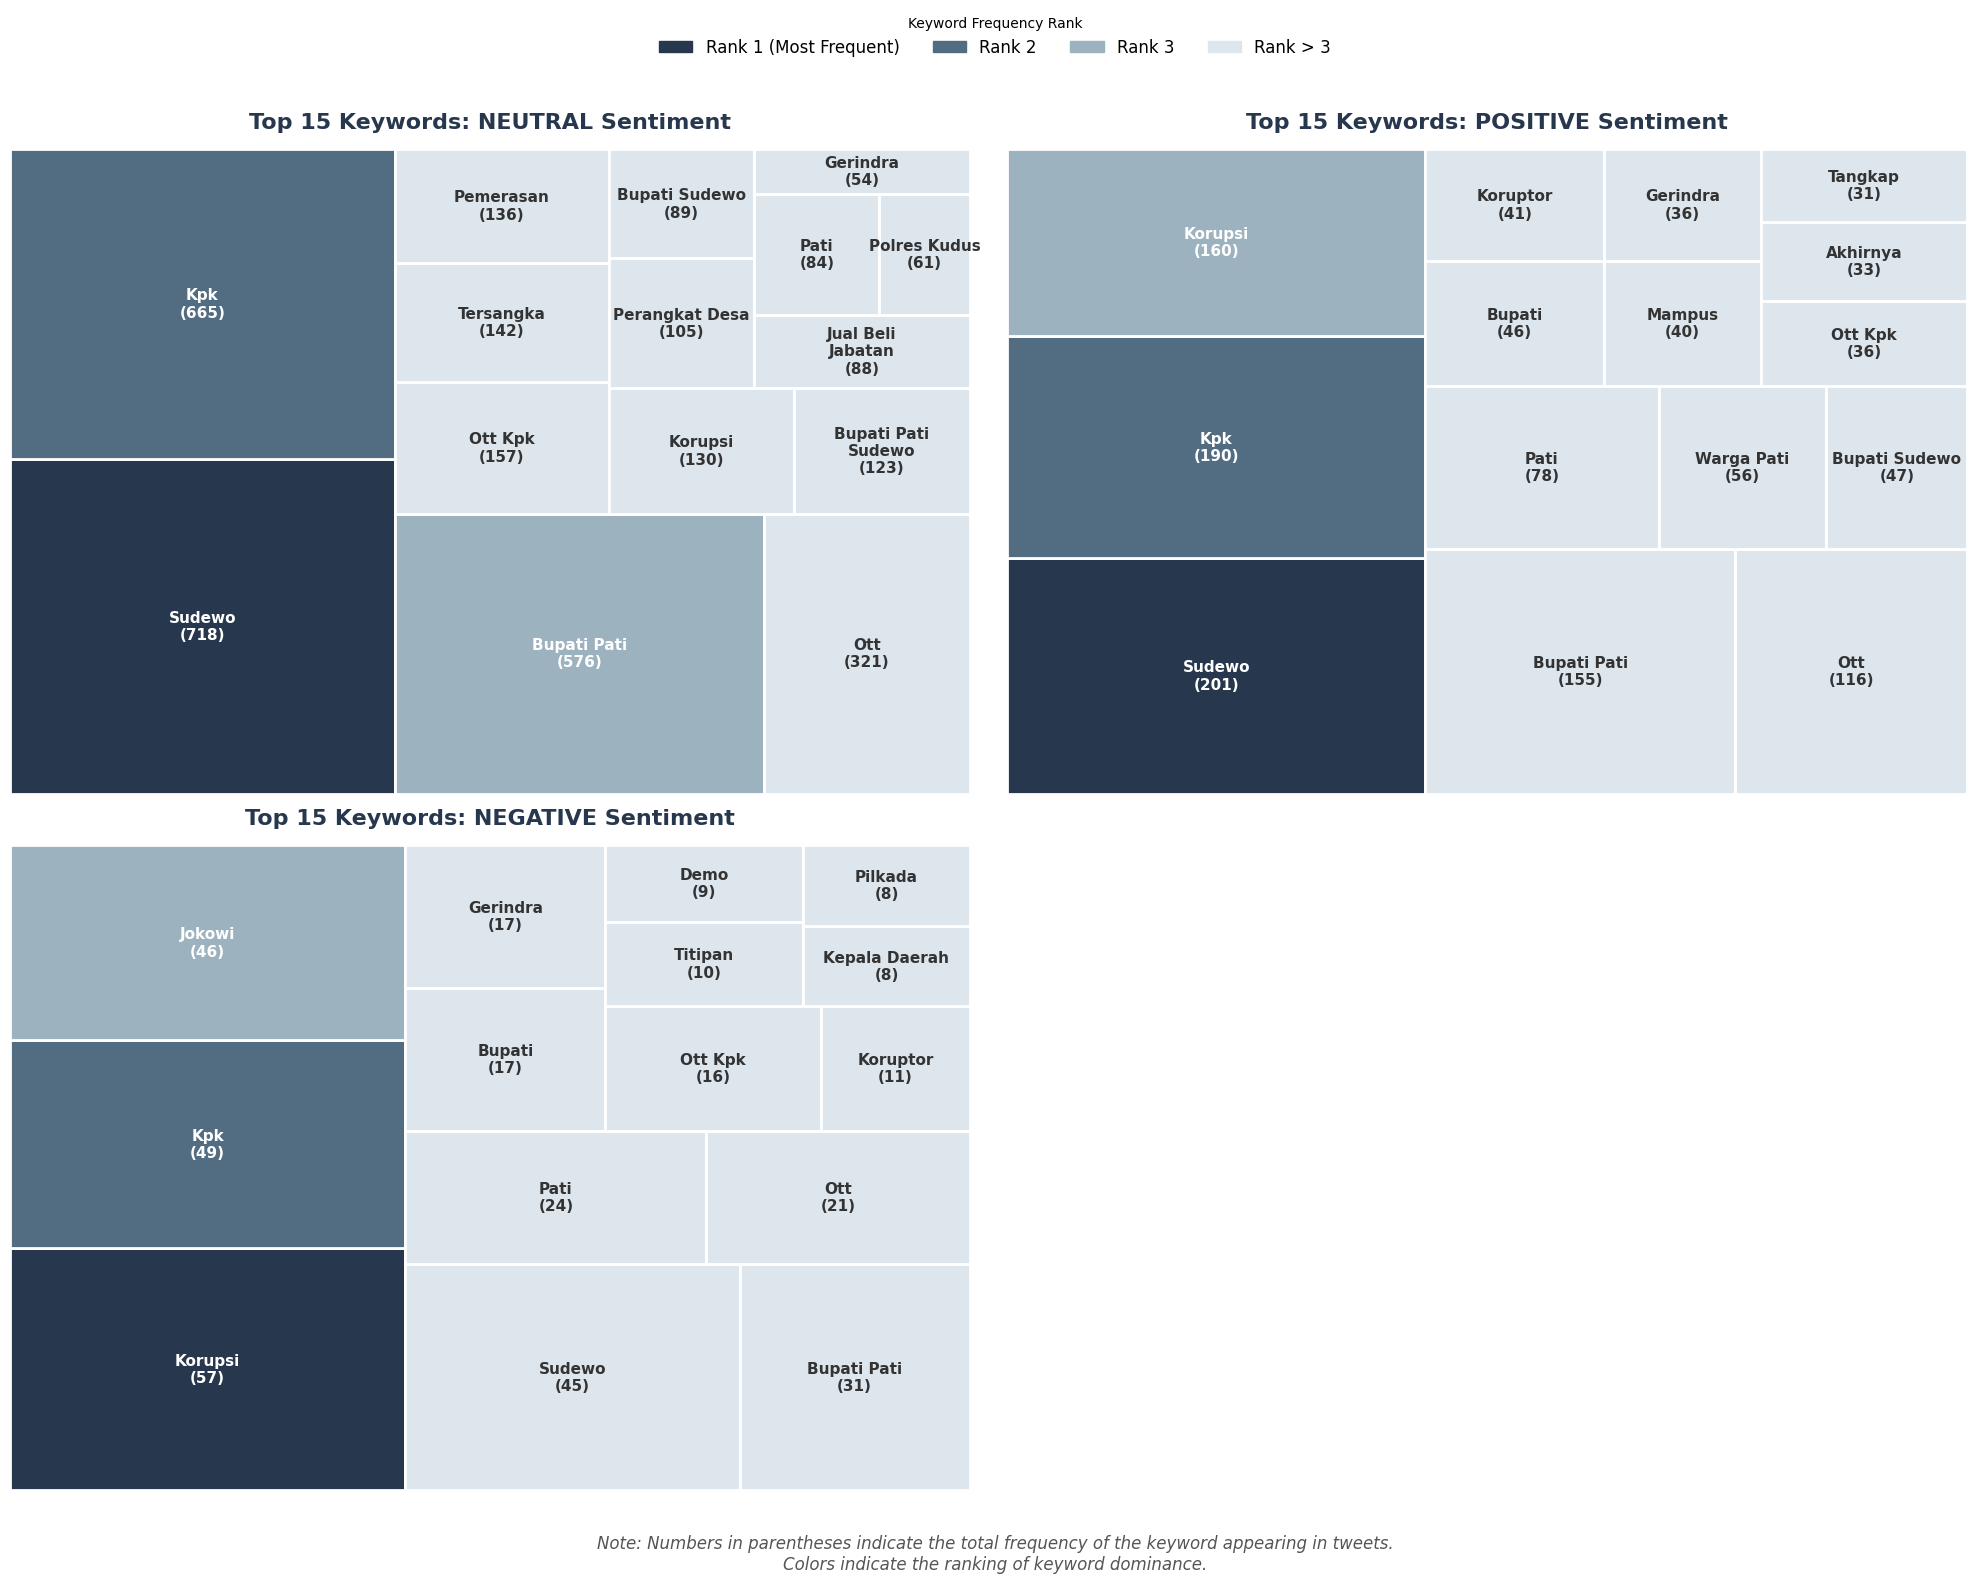

In [44]:
# filter non-null keywords
df_keywords = df_pati_final.dropna(subset=['sentiment_keywords']).copy()

# split comma-separated keywords into a list
df_keywords['keyword_list'] = df_keywords['sentiment_keywords'].str.split(',')

# explode list into individual rows (one row per keyword)
df_exploded = df_keywords.explode('keyword_list')

# clean whitespace and normalize text (title case)
df_exploded['keyword_clean'] = df_exploded['keyword_list'].str.strip().str.title()

# remove empty strings if any
df_exploded = df_exploded[df_exploded['keyword_clean'] != '']

# 3 subplots for 3 sentiments (positive, negative, neutral) -> 2x2 layout is good (1 empty)
fig, axes = plt.subplots(2, 2, figsize=(20, 16), facecolor='white')
flat_axes = axes.flatten()

# get unique sentiments to iterate
unique_sentiments = df_exploded['sentiment_llm'].unique()

# plotting
for i, sentiment in enumerate(unique_sentiments):
    if i >= len(flat_axes): break
    
    ax = flat_axes[i]
    
    # filter per sentiment & count top 15 keywords
    sentiment_topics = df_exploded[df_exploded['sentiment_llm'] == sentiment]['keyword_clean'].value_counts().head(15)
    
    # color logic (rank based)
    plot_colors = []
    text_colors = []
    
    for idx in range(len(sentiment_topics)):
        if idx == 0:
            # rank 1
            plot_colors.append('#27374D')
            text_colors.append('white')
        elif idx == 1:
            # rank 2
            plot_colors.append('#526D82')
            text_colors.append('white')
        elif idx == 2:
            # rank 3
            plot_colors.append('#9DB2BF')
            text_colors.append('white')
        else:
            # rank > 3
            plot_colors.append('#DDE6ED')
            text_colors.append('#333333')
            
    # label logic
    labels = []
    for label, count in zip(sentiment_topics.index, sentiment_topics.values):
        # wrap text if longer than 15 chars
        wrapped_label = textwrap.fill(label, width=15)
        labels.append(f"{wrapped_label}\n({count})")
        
    # squarify plot
    squarify.plot(sizes=sentiment_topics.values, label=labels, ax=ax,
                  alpha=1, color=plot_colors,
                  text_kwargs={'fontsize': 11, 'weight': 'bold', 'wrap': True},
                  bar_kwargs={'edgecolor': 'white', 'linewidth': 2})
                  # added white border for cleaner look
    
    # apply text colors manually
    for txt, t_color in zip(ax.texts, text_colors):
        txt.set_color(t_color)
        
    # styling
    ax.set_title(f"Top 15 Keywords: {sentiment} Sentiment", fontsize=16, weight='bold', color='#27374D', pad=15)
    ax.axis('off')

# hide unused axes (if any, e.g. the 4th subplot)
for j in range(len(unique_sentiments), len(flat_axes)):
    flat_axes[j].axis('off')

# create legend handles manually
legend_handles = [
    mpatches.Patch(color='#27374D', label='Rank 1 (Most Frequent)'),
    mpatches.Patch(color='#526D82', label='Rank 2'),
    mpatches.Patch(color='#9DB2BF', label='Rank 3'),
    mpatches.Patch(color='#DDE6ED', label='Rank > 3')
]

# add legend to the figure (global)
fig.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, 0.99),
           ncol=4, frameon=False, fontsize=12, title="Keyword Frequency Rank")

# add explanatory note
note_text = "Note: Numbers in parentheses indicate the total frequency of the keyword appearing in tweets.\nColors indicate the ranking of keyword dominance."
plt.figtext(0.5, 0.01, note_text, ha='center', fontsize=12, style='italic', color='#555555')

# adjust rect to fit legend at top and note at bottom
plt.tight_layout(rect=[0, 0.05, 1, 0.93])
plt.show()

In [46]:
df_pati_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2386 entries, 0 to 2385
Data columns (total 23 columns):
 #   Column              Non-Null Count  Dtype              
---  ------              --------------  -----              
 0   id                  2386 non-null   int64              
 1   conversation_id     2386 non-null   int64              
 2   source_tweet_id     1117 non-null   float64            
 3   relation_type       2386 non-null   object             
 4   text                2386 non-null   object             
 5   author              2386 non-null   object             
 6   author_location     1449 non-null   object             
 7   created_at          2386 non-null   datetime64[ns, UTC]
 8   like_count          2386 non-null   int64              
 9   reply_count         2386 non-null   int64              
 10  retweet_count       2386 non-null   int64              
 11  quote_count         2386 non-null   int64              
 12  view_count          2386 non-null 

In [47]:
from wordcloud import WordCloud

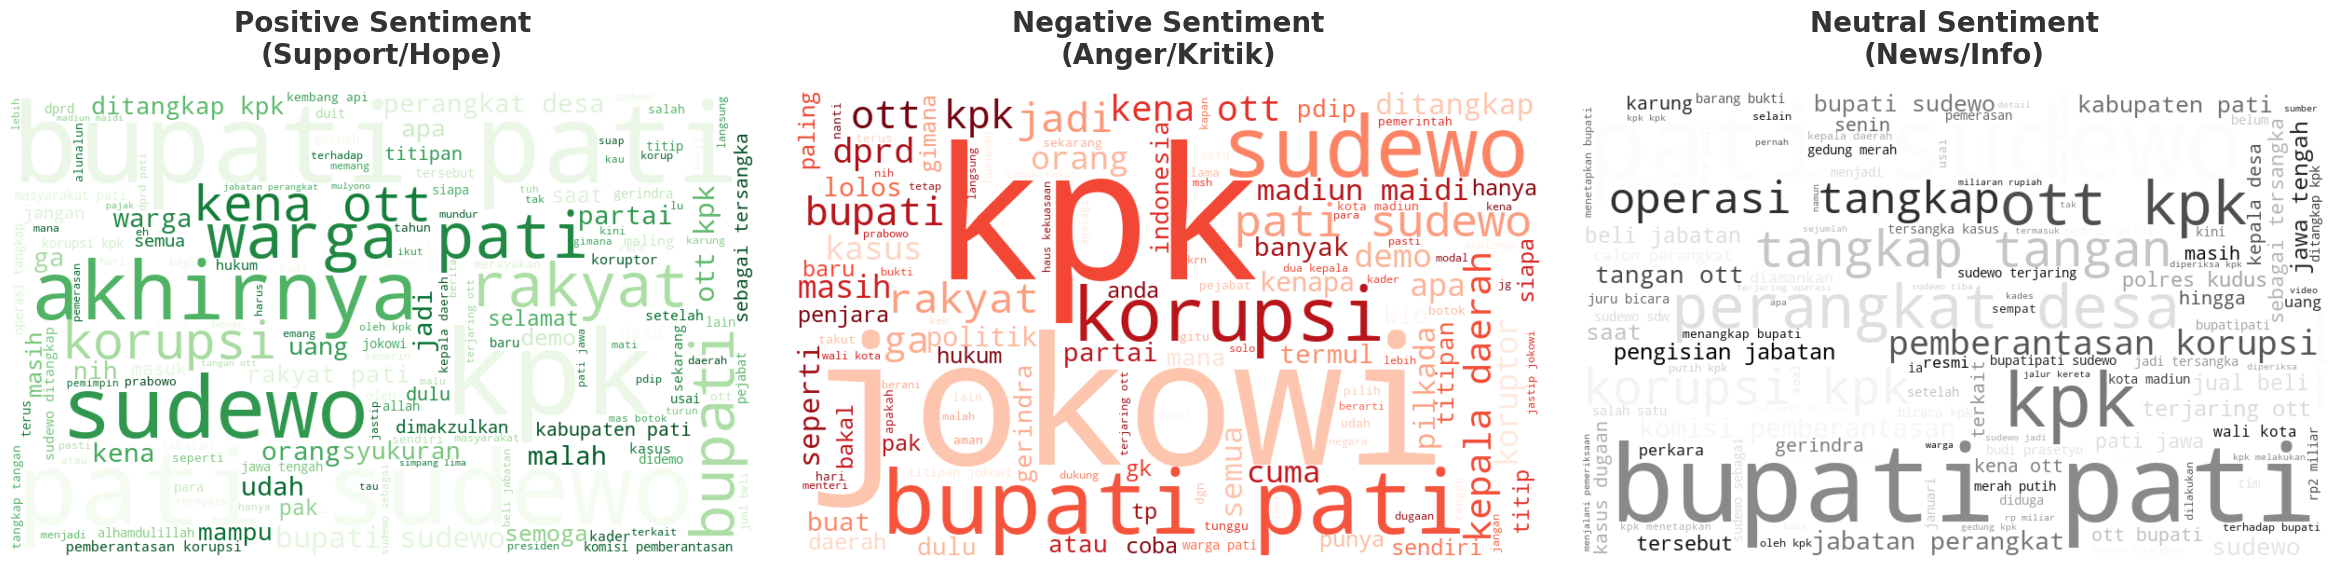

In [48]:
# some of stopword (not all, of course hehe)
custom_stopwords = set([
    'yg', 'yang', 'dan', 'di', 'ke', 'dari', 'ini', 'itu', 'ada', 'adalah',
    'ya', 'gak', 'tidak', 'bukan', 'tapi', 'akan', 'sudah', 'telah',
    'untuk', 'kepada', 'bisa', 'karena', 'kalau', 'jika', 'rt', 'user',
    'url', 'https', 't', 'co', 'amp', 'nan', 'dengan', 'dalam', 'pada',
    'saya', 'kamu', 'dia', 'mereka', 'kita', 'kami', 'mau', 'lagi',
    'aja', 'saja', 'kok', 'sih', 'dong', 'kan', 'lah', 'pun', 'n',
    'nya', 'kalo', 'biar', 'si', 'sama', 'juga'
])

# ensure clean_text is string and handle nans
df_pati_final['clean_text'] = df_pati_final['clean_text'].astype(str).fillna('')

# split data by sentiment
text_positive = " ".join(df_pati_final[df_pati_final['sentiment_llm'] == 'POSITIVE']['clean_text'])
text_negative = " ".join(df_pati_final[df_pati_final['sentiment_llm'] == 'NEGATIVE']['clean_text'])
text_neutral = " ".join(df_pati_final[df_pati_final['sentiment_llm'] == 'NEUTRAL']['clean_text'])

# visualization setup
fig, axes = plt.subplots(1, 3, figsize=(24, 8), facecolor='white')

# helper function for consistent styling
def plot_cloud(text, ax, colormap, title):
    if len(text) == 0:
        ax.text(0.5, 0.5, "no data", ha='center', va='center')
        ax.axis('off')
        return

    wc = WordCloud(
        width=800, 
        height=500,
        background_color='white', # cleaner for reports
        stopwords=custom_stopwords,
        colormap=colormap,        # distinct color for each sentiment
        min_font_size=10,
        max_words=150,            # limit words to avoid clutter
        collocations=True,        # enable bigrams (e.g., 'titip pati')
        random_state=42
    ).generate(text)
    
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(title, fontsize=20, fontweight='bold', color='#333333', pad=20)
    ax.axis('off')

#generate plot
# positive (greens)
plot_cloud(text_positive, axes[0], 'Greens', 'Positive Sentiment\n(Support/Hope)')

# negative (reds)
plot_cloud(text_negative, axes[1], 'Reds', 'Negative Sentiment\n(Anger/Kritik)')

# neutral (greys)
plot_cloud(text_neutral, axes[2], 'Greys', 'Neutral Sentiment\n(News/Info)')

# finishing
plt.tight_layout(pad=3)
plt.show()

Efek Jastip
- Bukti di Treemap (Negative Sentiment): Perhatikan kotak di Negative Sentiment. Keyword "Jokowi" muncul di Rank ke-3 (46 frekuensi), tepat di bawah "KPK" dan "Korupsi". Lebih spesifik lagi, muncul keyword "Titipan" (10 frekuensi) di cluster negatif.
- Kata "Jokowi" muncul sangat besar dan sentral di tengah-tengah kata "KPK", "Korupsi", dan "Partai".
- Hasil-hasil di atas mengonfirmasi bahwa publik menyarang "Legacy Endorsement"-nya. Publik marah karena sosok yang dulu "dititipkan" (di-endorse) oleh Presiden ternyata korupsi. Sentimen negatif ini adalah bentuk kekecewaan atas salah pilih/salah dukung.

Warna hijau (Positif) di sini murni berisi Euforia Penegakan Hukum, bukan dukungan personal.
- Keyword Kunci: Perhatikan kata "Akhirnya" (33) dan "Mampus" (40) di Treemap Positif, serta kata "Akhirnya" yang sangat besar di WordCloud Hijau.
- Kata "Akhirnya" mengandung makna psikologis yang dalam: Penantian Panjang. Ini menunjukkan bahwa masyarakat Pati sebenarnya sudah lama muak, terlebih dengan adanya kasus gagal pemakzulan sampai penangkapan aktivis, penagkapan karena terbukti OTT adalah keniscayaan bagi masyarakat pati. Kata "Mampus" dan "Syukuran" (di WordCloud) adalah ekspresi pelepasan emosi (katarsis) bahwa "doa orang terzalimi terkabul". Dengan kata lain, positif bukan mendukung bupati, tetapi mensyukuri tertangkap bupati. Citra politiknya sudah rusak

Selain Jokowi, sentimen negatif juga menyoroti kendaraan politik tersangka.
- Keyword "Gerindra" (17), "Pilkada" (8), dan "Partai" muncul di area negatif.
- Publik menganggap kasus ini mencoreng integritas partai pengusung. Ada kekhawatiran atau sinisme bahwa korupsi ini berkaitan dengan pendanaan politik ("Modal Pilkada" atau "Balik Modal").

Cluster netral sangat berguna untuk menjelaskan "Apa yang sebenarnya terjadi?" secara faktual.
- Data: Muncul keyword spesifik: "Jual Beli Jabatan" (88), "Pemerasan" (136), "Perangkat Desa" (105).
- Ini memperjelas kasusnya. Sudewo tidak hanya korupsi proyek fisik, tapi melakukan "Perdagangan Kekuasaan" (Trading in Influence) dengan memeras kepala desa atau jual beli posisi. Ini jenis korupsi yang langsung dirasakan dampaknya oleh birokrasi bawah, sehingga wajar jika kemarahan publik (Negative Sentiment) begitu tinggi terhadap "Partai" dan "Titipan"

# Kesimpulan
Secara network, terlihat tidak ada upaya yang diarahkan kepada dukungan sudewo. Dengan kata lain, mostly twit positif merupakan suka cita, sementara negatif berisikan kekecawaan dan permintaan tanggung jawab kepada kendaraan politiknya, negara, dan manta kepala negara. Adapun poin-poin sentiment lainnya dapat disimpulkan sebagai berikut:

1. Vindikasi Publik (Positif): Dominasi kata "Akhirnya" dan "Syukuran" menandakan bahwa OTT ini adalah jawaban atas keresahan masyarakat yang sudah lama terpendam. Ini adalah perayaan runtuhnya impunitas.

2. Sanksi Sosial Politik (Negatif): Munculnya "Jokowi" dan "Titipan" sebagai top keyword negatif memvalidasi teori 'Boomerang Effect'. Endorsement politik masa lalu kini menjadi beban liabilitas. Publik menagih pertanggungjawaban moral kepada figur nasional dan partai (Gerindra) yang pernah memberikan legitimasi kepada tersangka.

3. Kejahatan Struktural (Netral): Percakapan berfokus pada "Jual Beli Jabatan" dan "Pemerasan", mengindikasikan kerusakan sistemik pada tata kelola birokrasi daerah.